# TS7

#### Rey Tomás, Lanzavechia Jerónimo, Alvarez Costa Iara, Gonzalo 
#### APS

## Introducción

El electrocardiograma (ECG) es una señal de muy baja amplitud, por lo que su registro es sensible a fuentes de contaminación. Se tiene un registro de un paciente durante una prueba de esfuerzo, y se reconocen las siguientes tres fuentes de ruido:

- **Movimiento de los electrodos**, de alta frecuencia.
- **Ruido muscular**, de alta frecuencia.
- **Movimiento de la línea de base**, inducido en parte por la respiración, de baja frecuencia.

Dado que el contenido espectral útil del ECG se encuentra en una banda acotada, mientras que estas perturbaciones se ubican en sus extremos, estas distorsiones pueden ser atenuadas por un filtro pasabanda. El objetivo es obtener una señal suave y con nivel isoeléctrico nulo, cuya morfología sea comparable con la de los latidos promedio de referencia (normal y de origen ventricular).

Parte a)
Dado que el contenido espectral útil del ECG se encuentra en una banda acotada, mientras que estas perturbaciones se ubican en sus extremos, estas distorsiones pueden ser atenuadas por un filtro pasabanda. El objetivo es obtener una señal suave y con nivel isoeléctrico nulo, cuya morfología sea comparable con la de los latidos promedio de referencia (normal y de origen ventricular).

Para ello se establece una plantilla de diseño a partir del ancho de banda del ECG estimado en la TS5 (Aproximadamente unos 22 kHz), y se diseñan y comparan filtros IIR (aproximaciones de Butterworth, Chebyshev tipo II y Cauer) y FIR (métodos de ventanas y cuadrados mínimos), todos implementados con scipy.signal. Finalmente, se evalúa el desempeño de cada filtro, verificando que atenue el ruido que deseamos eliminar sin distorsionar la sección de la señal que es de nuestro interés.

In [3]:
import numpy as np
from scipy import signal as sig

import matplotlib.pyplot as plt
   
import scipy.io as sio
from scipy.io.wavfile import write
from matplotlib.patches import Rectangle

In [4]:
##Obtención de la señal ECG
##################
## ECG con ruido
##################

fs=1000 #definimos la frecuencia de muestreo en 1000 hz

# para listar las variables que hay en el archivo
sio.whosmat('ECG_TP4.mat')
mat_struct = sio.loadmat('./ECG_TP4.mat')

ecg_one_lead = mat_struct['ecg_lead']*1.0
ecg_one=ecg_one_lead[5000:12000].flatten()
#ecg_one_lead=ecg_one
N = len(ecg_one_lead)
y_min, y_max = -100, 5

In [5]:
#############
# Plantilla #
#############
 

nyq_frec = fs/2
ripple = 1 # dB
atenuacion = 40 # dB
 
ws1 = 2 # Hz
wp1 = 5 # Hz
wp2 = 25 # Hz
ws2 = 35 # Hz
wp=[wp1, wp2]
ws=[ws1, ws2]

 # PARTE B
Para hallar la frecuencia de paso, wp1 y wp2, las mismas se fijaron 5 y 25 Hz como margenes interiores, respectivamente. En la TS5, se determinó que el ancho de banda de la señal ECG que se está trabajando es de unos 22 hz, por lo que con este rango se asegura atrapar todo el contendio espectral

Para hallar la frecuencia de rechazo, ws1 y ws2, se establecieron como márgenes exteriores 2 y 35 Hz, respectivamente. El motivo de estas selecciones es que, a baja frecuencia, el movimiento de la linea base inducido por la respiración genera ruido que se busca atenuar. Mismamente, luego de los 35 hz también hay ruido, del tipo muscular y por movimientos del electrodo

El ripple en la banda de paso se estableció en 1 dB ya que es la máxima variación que quiero permitirle a mi señal dentro de la banda de paso

La atenuación en la banda de rechazo se estableció en 40 dB para asegurarme de que las fuentes de ruido mencionadas queden atenuadas y no afecten la señal de interés.

# Parte C 



# Diseño los filtros IIR

Uso la función iirdesign para armar los filtros ir. wp y ws entran como listas de elementos, y pido que devuelva una variable sos, es decir, second order sections, que es el filtro partido en una cascada de secciones de segundo orden. 

In [17]:
sos_butt = sig.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='butter', fs=fs, output = 'sos')
sos_cheby2 = sig.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='cheby2', fs = fs, output = 'sos')
sos_cauer = sig.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='cauer', fs = fs, output = 'sos')

In [7]:
#Función para calcular respuesta

def calc_resp(sos, leg_str, fig_n_axes):

    # Respuesta en frecuencia en Hz, de 0 a Nyquist
    f, h = sig.freqz_sos(sos, worN=8192, fs=fs)

    # Módulo en dB y fase desenrollada en radianes
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))

    # Retardo de grupo: -d(fase)/d(omega), en segundos
    omega = 2 * np.pi * f
    retardo_s = -np.gradient(fase_rad, omega)

    # Donde el filtro rechaza la señal, el retardo no es significativo
    umbral_db = -80
    valido = modulo_db > umbral_db
    retardo_s_plot = np.where(valido, retardo_s, np.nan)

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # --- Módulo ---
    ax_mod.plot(f, modulo_db, linewidth=1.5, label=leg_str)
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_mod.grid(True)
    ax_mod.legend()

    # --- Fase ---
    ax_fase.plot(f, fase_rad, label=leg_str, linewidth=1.2)
    for w in wp:
        ax_fase.axvline(w, color="gray", linestyle=":")
    for w in ws:
        ax_fase.axvline(w, color="gray", linestyle="--")
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)
    ax_fase.legend()

    # --- Retardo de grupo (figura 2) ---
    plt.figure(2)
    plt.plot(f, retardo_s_plot, label=leg_str)
    for w in wp:
        plt.axvline(w, color="orange", linestyle="--")
    for w in ws:
        plt.axvline(w, color="red", linestyle=":")
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Retardo de grupo (s)")
    plt.title("Retardo de grupo del filtro IIR")
    plt.grid(True)
    plt.legend()

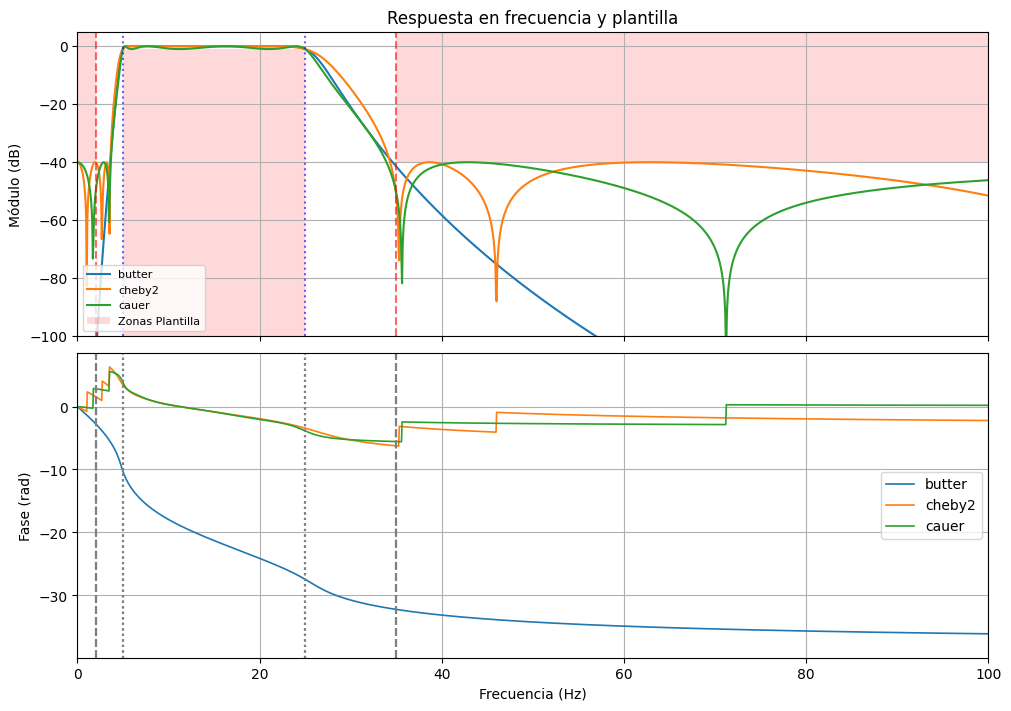

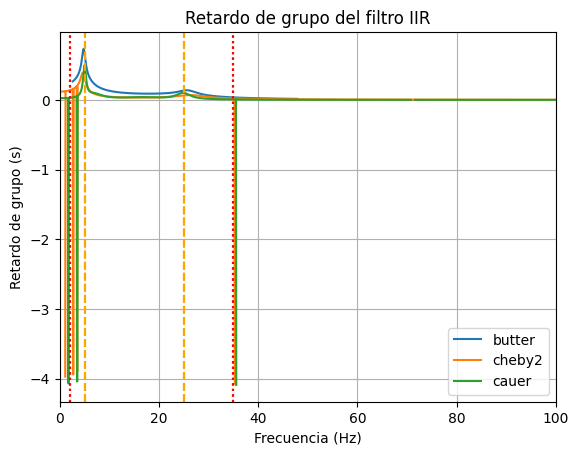

In [20]:
# Graficar la respuesta de los filtros IIR
plt.close('all')

fig_n_axes = plt.subplots(
    2, 1, sharex=True, num=1, figsize=(10, 7), constrained_layout=True
)

calc_resp(sos_butt,   'butter', fig_n_axes)
calc_resp(sos_cheby2, 'cheby2', fig_n_axes)
calc_resp(sos_cauer,  'cauer',  fig_n_axes)

# Plantilla sobre el gráfico de módulo
ax_mod = fig_n_axes[1][0]

# Zona prohibida en rechazo: de -atenuacion hacia arriba
ax_mod.add_patch(Rectangle((0, -atenuacion), ws1, y_max + atenuacion,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx"))
ax_mod.add_patch(Rectangle((ws2, -atenuacion), nyq_frec - ws2, y_max + atenuacion,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx"))

# Franja prohibida bajo el ripple, en la banda de paso
ax_mod.add_patch(Rectangle((wp1, y_min), wp2 - wp1, -ripple - y_min,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx",
                           label='Zonas Plantilla'))

# Límites de las bandas
for w in wp:
    ax_mod.axvline(w, color="blue", linestyle=":", alpha=0.6)
for w in ws:
    ax_mod.axvline(w, color="red", linestyle="--", alpha=0.6)

ax_mod.legend(loc="lower left", fontsize=8)
ax_mod.set_xlim(0, 100)          
# Retardo de grupo (figura 2)
plt.figure(2)
plt.xlim(0, 100)                 
plt.show()   

## Módulo

Los tres filtros cumplen con lo que pide la plantilla, un ripple menor a 1 dB en la zona de paso, y atenuación mayor a 40 dB fuera de ellas. En las zonas de paso, Cauer se despega ligeramente y tienen más ripple que butter y chebby2, que son completamente planos en esa región. En ambas zonas de rechazo se puede ver que cauer y chebby tienen ceros de transmisión en el eje de frecuencias, que hace que la respuesta de su módulo rebote y se mantenga cerca de los -40dB. Por su parte, butterworth cae de forma contina y rápidamente llega incluso debajo de -100dB. En las zonas de transición los 3 se comportan de manera similar, con el cheby2 teniendo menos atenuación que los otros, y una curva no tan lineal.

## Fase y Retardo

La fase de ninguno de los 3 filtros es lineal en la banda de paso. Esto se traduce en que el retardo del grupo no sea constante y presente picos en los bordes de las bandas, alrededor de las frecuencias de paso y de atenuación. Esto demuestra que, si bien los filtros IIR atenuan el módulo de la señal de manera satisfactoria, si fuéramos a aplicar estos filtros a la señal, veríamos grandes distorsiones en la ECG alrededor de los 2 y 35 hz. 

# Filtros FIR
La filtros FIR son filtros de respuesta finita. Esto se debe a que la respuesta depende de muestras anteriores, a diferencia de los filtros IIR que poseen realimentación, por lo que existe un retardo en la respuesta del filtro al comienzo del filtrado. Uno de los efectos de esto es que la respuesta de fase se mantiene lineal en la banda de paso. 
Se usa la función firwin2 para armar los filtros. Es necesario implementar vectores de frecuencias y de ganancias para la construcción del filtro.
frecs contiene el vector de frecuencias de paso y de corte de la plantilla, normalizadas por Nyquist. gains contiene las ganancias deseadas en cada frecuencia del filtro. Se construye con las ganancias en db y luego se despejan sus valores en veces para aplicarlos a la función. El número de taps representa la longitud de la ventana a trabajar. Se busca una cantidad de taps particular para hacer coincidir al filtro con la plantilla de la actividad.
En el caso del fir de ventana [tal] el número de taps es [tal]
En el caso del fir de cuadrados mínimos, el número de taps es [tal]
Se implementan ambos filtros y se comparan con la señal original.

In [18]:
# Funcion para graficar la respuesta de los filtros FIR

def calc_resp_fir(coefs, leg_str, fig_n_axes):

    # Respuesta en frecuencia en Hz, de 0 a Nyquist
    f, h = sig.freqz(coefs, worN=8192, fs=fs)

    # Módulo en dB y fase desenrollada en radianes
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))

    # Retardo de grupo: -d(fase)/d(omega), en segundos
    omega = 2 * np.pi * f
    retardo_s = -np.gradient(fase_rad, omega)

    # Donde el filtro rechaza la señal, el retardo no es significativo
    umbral_db = -80
    valido = modulo_db > umbral_db
    retardo_s_plot = np.where(valido, retardo_s, np.nan)

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # --- Módulo ---
    ax_mod.plot(f, modulo_db, linewidth=1.5, label=leg_str)
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_mod.grid(True)
    ax_mod.legend()

    # --- Fase ---
    ax_fase.plot(f, fase_rad, label=leg_str, linewidth=1.2)
    for w in wp:
        ax_fase.axvline(w, color="gray", linestyle=":")
    for w in ws:
        ax_fase.axvline(w, color="gray", linestyle="--")
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)
    ax_fase.legend()

    # --- Retardo de grupo (figura 2) ---
    plt.figure(2)
    plt.plot(f, retardo_s_plot, label=leg_str)
    for w in wp:
        plt.axvline(w, color="orange", linestyle="--")
    for w in ws:
        plt.axvline(w, color="red", linestyle=":")
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Retardo de grupo (s)")
    plt.title("Retardo de grupo del filtro IIR")
    plt.grid(True)
    plt.legend()

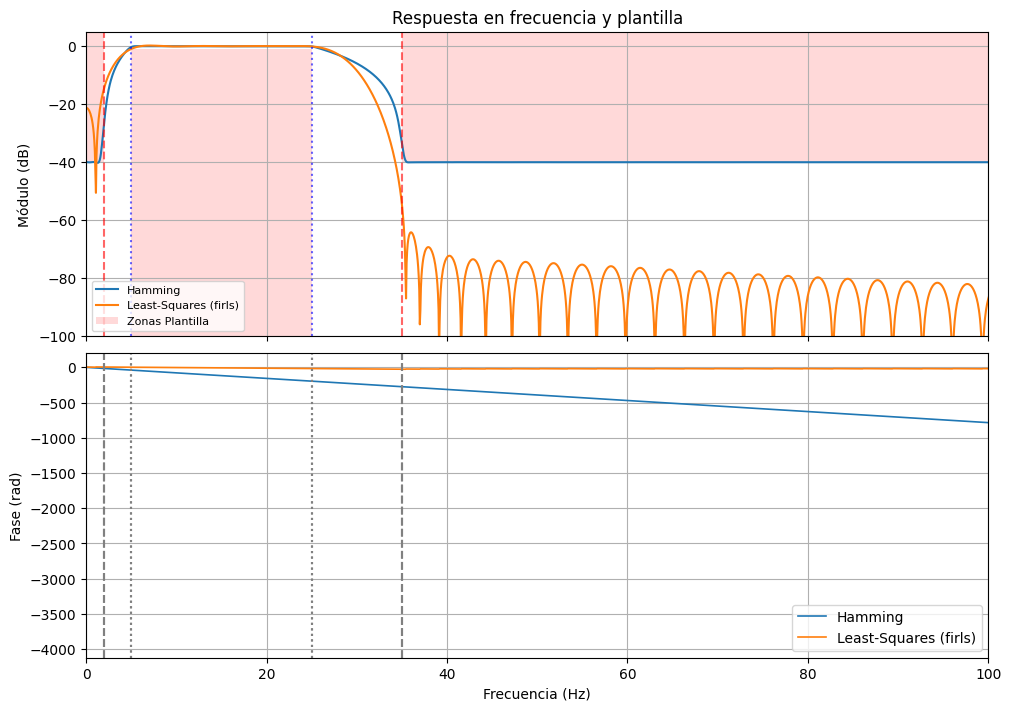

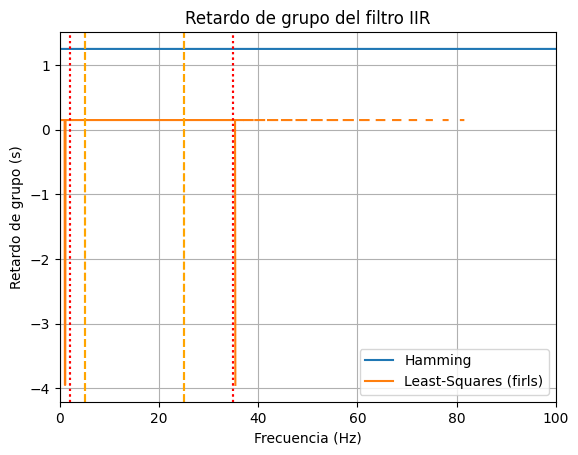

In [19]:
##ARMADO DE FIRS
##hamming
numtaps_hamming = 2501  

# plantilla normalizada a Nyquist en dB
frecs = np.array([0.0,         ws1,         wp1,     wp2,     ws2,         nyq_frec   ]) / nyq_frec
gains = np.array([-atenuacion, -atenuacion, 0, 0, -atenuacion, -atenuacion])#disminuyo el máximo ripple permitido a 0 dB así 
#puedo asegurarme de que no se atenue de mas en los límites de la banda de paso

##cuadrados minimos
desired = np.array([0.0,0.0,1.0,1.0,0.0,0.0])
numtaps_firls = 301

# convertimos a veces para las funciones de diseño
gains = 10**(gains/20)

coefs_fir_hamming = sig.firwin2(numtaps_hamming, frecs, gains,window='hamming')
coefs_firls = sig.firls(numtaps_firls, frecs*nyq_frec, desired,fs=fs)

fig_fir_axes = plt.subplots(
    2, 1, sharex=True, figsize=(10, 7), constrained_layout=True
)

calc_resp_fir(coefs_fir_hamming, 'Hamming', fig_fir_axes)
calc_resp_fir(coefs_firls, 'Least-Squares (firls)', fig_fir_axes)

#Superponer la plantilla en el gráfico de módulo de los FIR
# Plantilla sobre el gráfico de módulo
ax_mod = fig_fir_axes[1][0]

# Zona prohibida en rechazo: de -atenuacion hacia arriba
ax_mod.add_patch(Rectangle((0, -atenuacion), ws1, y_max + atenuacion,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx"))
ax_mod.add_patch(Rectangle((ws2, -atenuacion), nyq_frec - ws2, y_max + atenuacion,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx"))

# Franja prohibida bajo el ripple, en la banda de paso
ax_mod.add_patch(Rectangle((wp1, y_min), wp2 - wp1, -ripple - y_min,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx",
                           label='Zonas Plantilla'))

# Límites de las bandas
for w in wp:
    ax_mod.axvline(w, color="blue", linestyle=":", alpha=0.6)
for w in ws:
    ax_mod.axvline(w, color="red", linestyle="--", alpha=0.6)

ax_mod.legend(loc="lower left", fontsize=8)
ax_mod.set_xlim(0, 100)          
# Retardo de grupo (figura 2)
plt.figure(2)
plt.xlim(0, 100)                 
plt.show()                         

## Módulo

En la banda de paso (de 5 a 25 Hz) ambos filtros son prácticamente planos en 0 dB, sin mostrar ripple. En la transición superior (25 a 35 Hz), el método de cuadrados mínimos cae más rápido y con mayor atenuación que Hamming.

En la zona de rechazo superior (>35 Hz), Hamming se estabiliza en ≈-40 dB. Cumple la plantilla, pero justo en el límite y sin margen, porque -40 dB fue la ganancia objetivo del diseño. Cuadrados mínimos baja hasta alrededor de unos -70 dB con lóbulos de amplitud casi constante, lo que da un margen de unos 30 dB por sobre lo requeriod por la plantilla.

En la zona de rechazo inferior (0 a 2 Hz) Hamming queda otra vez cerca de -40 dB. Cuadrados mínimos, en cambio, parte de ≈-20 dB en 0 Hz y llega a un mínimo de ≈-50 dB cerca de 2 Hz, por lo que no cumple la plantilla en el extremo inferior. Esto importa porque ahí está la deriva de la línea de base, y es consistente con lo observado en la parte D, donde este filtro dejó la base elevada en el tramo de mayor deriva.

## Fase y retardo

Ambos filtros tienen fase lineal: la fase desenrollada es una recta de pendiente negativa en todo el rango, por lo que el retardo de grupo es constante. Esto significa que la forma de onda no se distorsiona, solo se retrasa. A diferencia de los IIR, no hace falta filtfilt que los corrija.

La pendiente de Hamming es mucho mayor (700 rad a 100 Hz) que la de cuadrados mínimos, que se ve casi plana en esta escala. El retardo de Hamming es de ≈1,25 s contra ≈0,15 s, que equivalen a (N-1)/2 muestras a fs = 1000 Hz. Hamming necesita muchos más coeficientes, por lo que su retardo es unas 8 veces mayor. Este retardo se compensó desplazando la señal filtrada en la parte D.

# Paso de las señales por los filtros

Con los filtros ya armados y cumpliendo con las plantillas, los usaremos para filtrar las señales y ver como se desempeñan.

In [25]:
#Paso de la señal por los IIR
ecg_one_1d=ecg_one.ravel()  #Uso Ravel para aplanarl ecg_one a un vector (7000,) para que sosfiltfilt pueda trabajarlo

ecg_filt_butt=sig.sosfiltfilt(sos_butt,ecg_one_1d)
ecg_filt_cheby2=sig.sosfiltfilt(sos_cheby2,ecg_one_1d)
ecg_filt_cauer=sig.sosfiltfilt(sos_cauer,ecg_one_1d)

In [26]:
# Función para comparar la señal original y las señales IIR filtradas juntas
def plotear_todas_iir_juntas(ecg_orig, dic_filtradas_iir):
    plt.figure(figsize=(14, 6))
    # Graficamos la señal original con ruido de fondo
    plt.plot(ecg_orig, label='ECG con ruido', color='gray', alpha=0.5, linewidth=1)
    
    colores = ['blue', 'green', 'purple']
    
    for (nombre, ecg_filt), color in zip(dic_filtradas_iir.items(), colores):
        # Como usamos sosfiltfilt (fase cero), no hay retardo que compensar
        plt.plot(ecg_filt, label=f'IIR ({nombre})', color=color, linewidth=1.1, alpha=0.85)
        
    plt.title("Comparación de señales ECG filtradas con filtros IIR")
    plt.xlabel("Muestras")
    plt.ylabel("Amplitud")
    plt.grid(True)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.xlim(3000, 4300)
    plt.show()

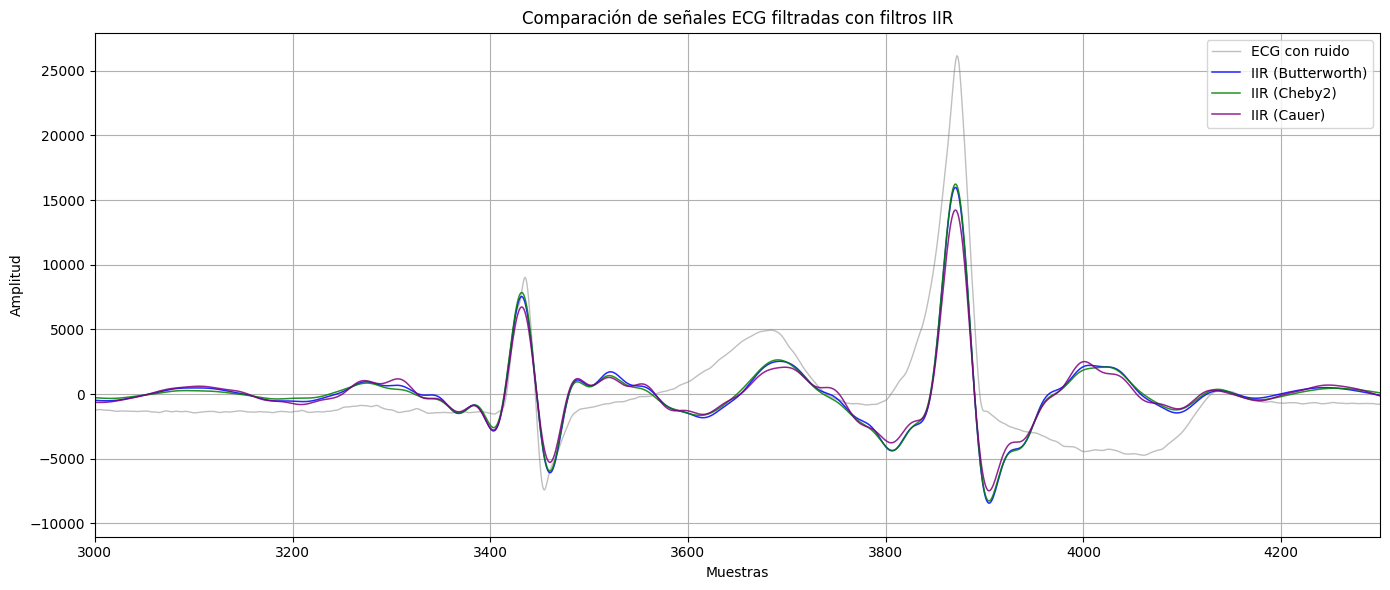

UsageError: Line magic function `%%ARMADO` not found.


In [27]:
# Señal pasada por los IIR
# Diccionario con las señales IIR filtradas
dic_iir_filtradas = {
    'Butterworth': ecg_filt_butt,
    'Cheby2': ecg_filt_cheby2,
    'Cauer': ecg_filt_cauer
}

# --- Llamamos a la función ---
plotear_todas_iir_juntas(ecg_one, dic_iir_filtradas)

%%ARMADO DE FIRS
numtaps_hamming = 1501  
numtaps_blackman = 1501  
numtaps_hann = 1501  
numtaps_boxcar = 2001

# plantilla normalizada a Nyquist en dB
frecs = np.array([0.0,         ws1,         wp1,     wp2,     ws2,         nyq_frec   ]) / nyq_frec
gains = np.array([-atenuacion, -atenuacion, 0, 0, -atenuacion, -atenuacion])#disminuyo el máximo ripple permitido a 0 dB así puedo asegurarme de que no se atenue de mas en los límites de la banda de paso

# convertimos a veces para las funciones de diseño
gains = 10**(gains/20)

coefs_fir_hamming = sig.firwin2(numtaps_hamming, frecs, gains,window='hamming')
coefs_fir_blackman = sig.firwin2(numtaps_blackman, frecs, gains,window='blackman')
coefs_fir_hann = sig.firwin2(numtaps_hann, frecs, gains,window='hann')
coefs_fir_boxcar = sig.firwin2(numtaps_boxcar, frecs, gains,window='boxcar')

def respuesta_frec (coefs):
    f, h = sig.freqz(coefs, worN=8192, fs=fs)
    return f,h

f_fir_hamming, h_fir_hamming = respuesta_frec(coefs_fir_hamming)
f_fir_blackman, h_fir_blackman = respuesta_frec(coefs_fir_blackman)
f_fir_hann, h_fir_hann = respuesta_frec(coefs_fir_hann)
f_fir_boxcar, h_fir_boxcar = respuesta_frec(coefs_fir_boxcar)

Los tres filtros IIR muestran resultados casi indistinguibles entre sí. En la señal original se puede ver una deriva en la línea de base que baja la señal a niveles por debajo del 0. Los filtros corrigen este fenómeno y dejan la línea de base más centrada en 0. Los pulsos QRS conservan su posición y forma porque la función filtfilt les da una fase cero y se puede observar mayor atenuación por parte de cauer y cheby2 en los picos

In [30]:
#Filtrado de la señal con FIR

ecg_filt_hamming = sig.lfilter(coefs_fir_hamming, 1.0, ecg_one)
ecg_filt_firls   = sig.lfilter(coefs_firls,   1.0, ecg_one)

In [34]:
# Función para comparar la señal original y las cuatro señales filtradas juntas

def ecg_filtrado_FIR(ecg_orig, filtradas_dict, numtaps_dict):
    plt.figure(figsize=(14, 6))
    # Graficamos la señal original de fondo (tomando como referencia el retardo máximo o medio)
    plt.plot(ecg_orig, label='ECG con ruido', color='gray', alpha=0.5, linewidth=1)
    
    colores = ['blue', 'green', 'orange', 'purple','red','yellow']
    
    for (nombre, ecg_filt), numtaps, color in zip(filtradas_dict.items(), numtaps_dict.values(), colores):
        retardo = (numtaps - 1) // 2
        ecg_filt_alineada = ecg_filt[retardo:]
        plt.plot(ecg_filt_alineada, label=f'Filtro {nombre}', color=color, linewidth=1.1, alpha=0.85)
        
    plt.title("Comparación de señales ECG filtradas con diferentes ventanas FIR")
    plt.xlabel("Muestras")
    plt.ylabel("Amplitud")
    plt.grid(True)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.xlim(0,1000)
    plt.show()

# Diccionarios para ordenar los datos y pasárselos a la función
dic_filtradas = {
    'Hamming': ecg_filt_hamming,
    'Least-Squares': ecg_filt_firls
}

dic_taps = {
    'Hamming': numtaps_hamming,
    'Least-Squares': numtaps_firls
}

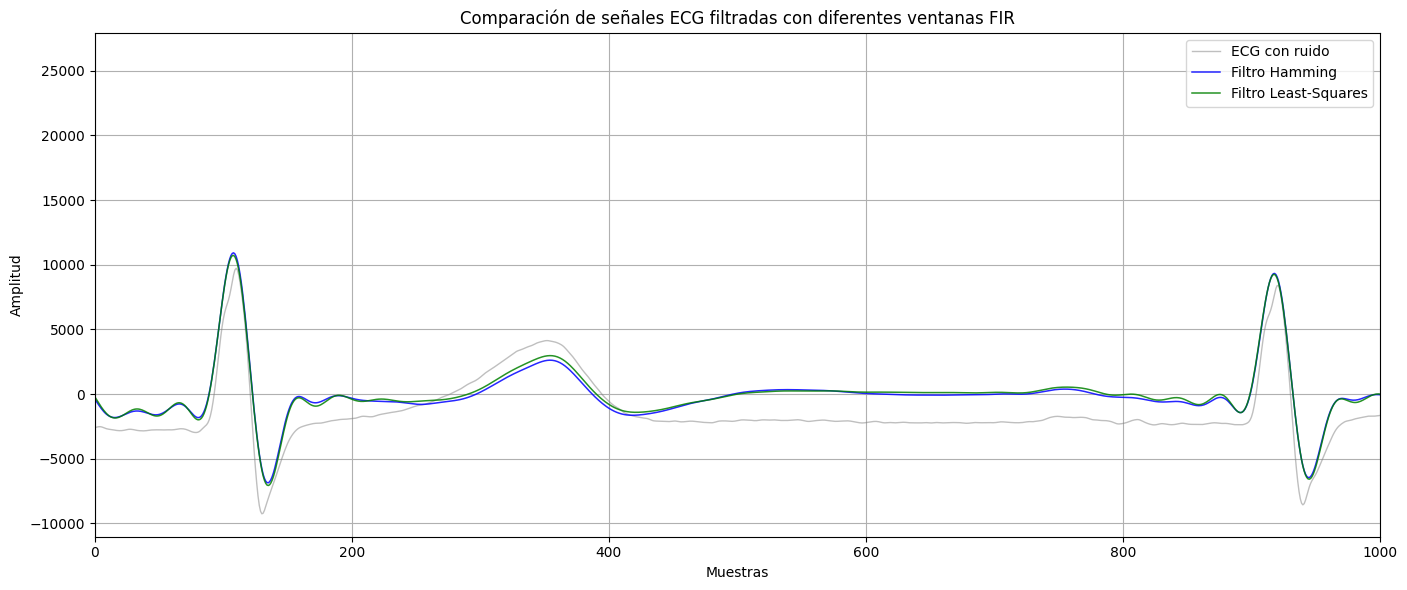

In [35]:
#Llamamos a la función

ecg_filtrado_FIR(ecg_one, dic_filtradas, dic_taps)

Hamming y Least-Squares dan resultados prácticamente superpuestos en todo el tramo. Ambos filtros ayudan a subir la línea de base y centrarla en 0, mantienen la composición y aumentan ligeramente la amplitud en las señales R y atenuan las T

# Parte D

In [51]:
fs_ecg = fs
ecg_full = ecg_one_lead.flatten()
cant_muestras = ecg_full.shape[0]

# IIR (fase cero con filtfilt, no hay demora)
ecg_butt_full  = sig.sosfiltfilt(sos_butt,  ecg_full)
ecg_cauer_full = sig.sosfiltfilt(sos_cauer, ecg_full)

# FIR (lfilter retrasa la señal (N-1)/2 muestras)
ecg_hamming_full = sig.lfilter(coefs_fir_hamming, 1.0, ecg_full)
ecg_firls_full   = sig.lfilter(coefs_firls,       1.0, ecg_full)

demora_hamming = (numtaps_hamming - 1) // 2
demora_firls   = (numtaps_firls - 1) // 2

ecg_hamming_full = np.concatenate([ecg_hamming_full[demora_hamming:], np.zeros(demora_hamming)])
ecg_firls_full   = np.concatenate([ecg_firls_full[demora_firls:],     np.zeros(demora_firls)])

def graficar_region(ini, fin):
    zoom_region = np.arange(max(0, int(ini)), min(cant_muestras, int(fin)), dtype=int)

    plt.figure(figsize=(12, 5))
    plt.plot(zoom_region, ecg_full[zoom_region], label='ECG', linewidth=2, color='gray', alpha=0.6)
    plt.plot(zoom_region, ecg_butt_full[zoom_region],    label='Butterworth')
    plt.plot(zoom_region, ecg_cauer_full[zoom_region],   label='Cauer')
    plt.plot(zoom_region, ecg_hamming_full[zoom_region], label='FIR Hamming')
    plt.plot(zoom_region, ecg_firls_full[zoom_region],   label='FIR Least-Squares')

    plt.title('ECG filtering example from ' + str(int(ini)) + ' to ' + str(int(fin)))
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    plt.grid(True)
    plt.legend()
    plt.show()

print("Muestras del registro:", cant_muestras)

Muestras del registro: 1129116


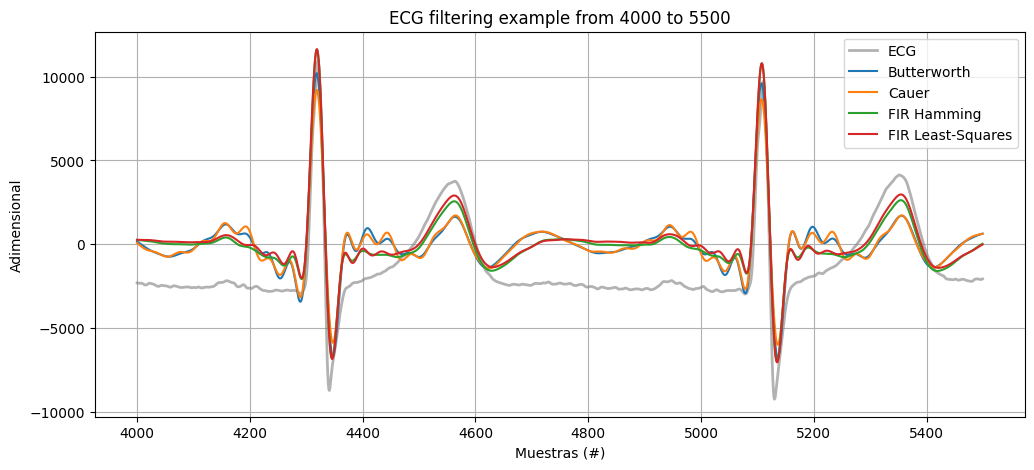

In [52]:
graficar_region(4000, 5500)

Entre las muestras 4000 y 5500, se ve un efecto similar al descripto previamente, donde el filtro consigue corregir un ruido de base que hace que la señal flote alrededor de -2500. Se aprecian 2 latidos, uno alrededor de la muestra 4300 y otro en 5100. Se conservan en posición al ser filtrados, lo que confirma que la fase cero de filtfilt y la alineación de los FIR es correcta. Se nota una leve variación en la amplitud, los métodos FIR parecen aplificar ligeramente de más las ondas R, mientras que butterworth y Cauer lo llevan un poco por debajo. Los valles posteriores a la señal R se centran en 0 para los FIR pero suben de más para las ventanas. Las ondas T se ven atenuadas para todos los casos. La posición de los latidos se va a mantener centrada en todas las muestras.

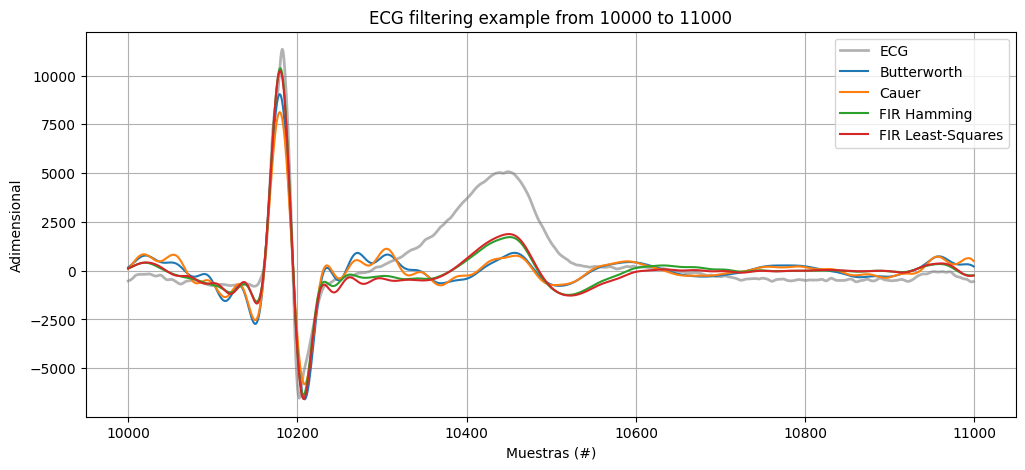

In [53]:
graficar_region(10000, 11000)


No hay tanto ruido de deriva por lo que no hay mucho que corregir en baja frecuencia, y se observa una gran atenuación en el tramo T. En esta zona solo se registró un latido, y también se consiguió corregir ruido entre las muestras 10600 y 10800

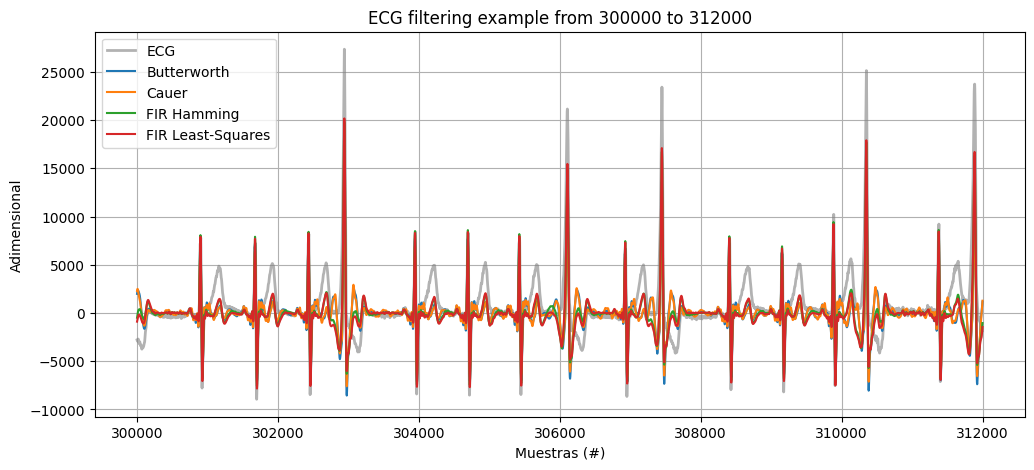

In [54]:
graficar_region(5*60*fs_ecg, 5.2*60*fs_ecg)

Esta región no tiene interferencias relevantes, los filtros ayudan a mantener el nivel isoeléctrico en 0. Sin embargo, parte de las ondas  T y P quedan fuertemente atenuadas, y algunas ondas R se reducen

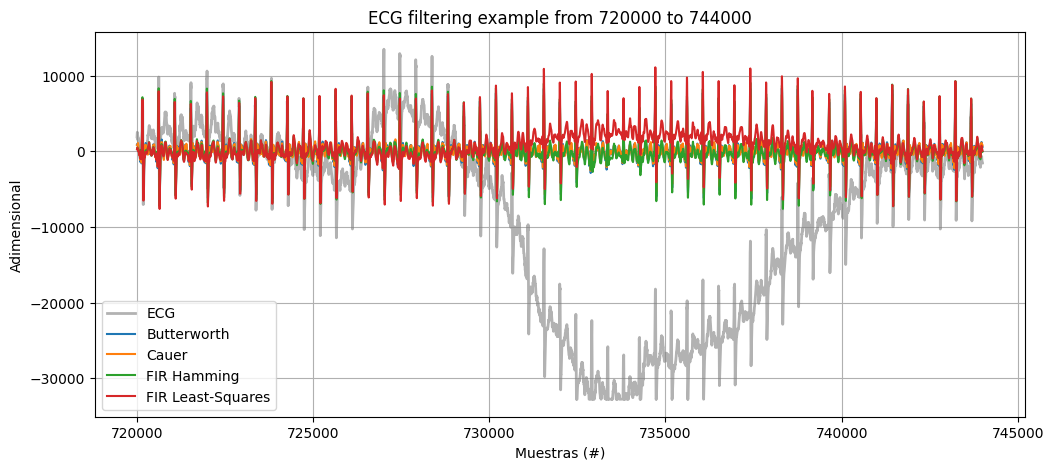

In [55]:
graficar_region(12*60*fs_ecg, 12.4*60*fs_ecg)

Aqui se observa la mayor deriva de la señal, y los filtros tratan de devolverlo al nivel isoeléctrico. Todos los filtros mitigan este ruido, aunque el método de cuadrados mínimos mantiene una cierta deriva 

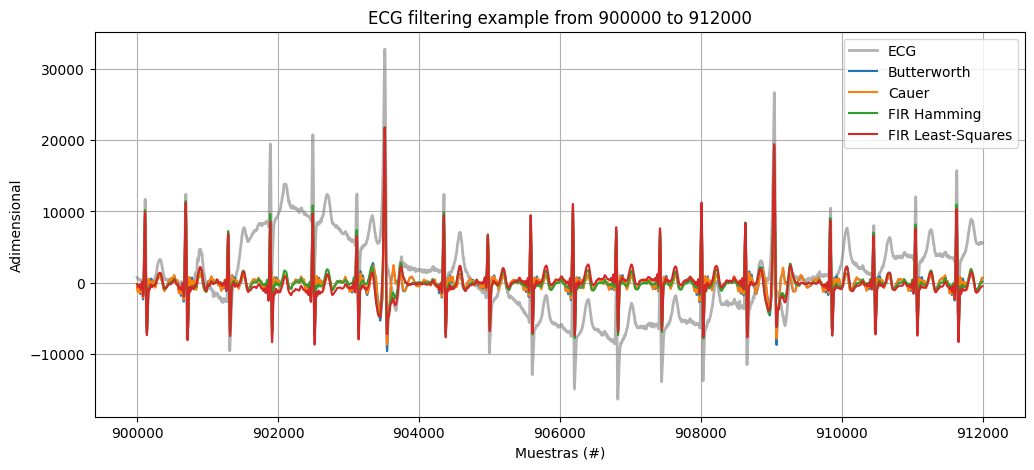

In [56]:
graficar_region(15*60*fs_ecg, 15.2*60*fs_ecg)

Se observan resultados similares al gráfico anterior, con ruido de base sacando los pulsos de su nivel isoeléctrico. Todos los filtros funcionan con una efectividad aceptable, volviendo la señal isoeléctrica, aunque atenuando las señales R

# Conclusiones 

Se pudo diagramar una plantilla genérica y forzar variados filtros digitales a cumplir con las exigencias. Los IIR necesitaron grados para satisfacer la plantilla, con Butterworth necesitando 12 secciones de segundo orden Cheby2 6 y Cauer 4.

Los filtros IIR teinen fase no lineal y su retardo de grupo tiene picos en los bordes de las bandas, por lo que debieron ser aplicados en conjunto con filtfilt para eliminar la distorsión y hacerlos de fase 0. Los filtros FIR, por su parte, sí tienen fase lineal y no distorsionan la forma de la onda, sino que solo la retrasan. Este efecto se puede compensar desplazando la señal.

Todos los filtros tuvieron un desempeño decente en el filtrado del ECG, mitigando la deriva y llevando a la señal a un punto isoeléctrico. También son capaces de mantener la posición de los pulsos, aunque en ciertas secciones atenuan de más o de menos, sin embargo siempre mantienen la forma del latidos.
